Name: Sania  
CMS ID: 023-24-0277   
Section: H  
GitHub Profile: https://github.com/saniamirani   
Kaggle Profile: https://www.kaggle.com/saniam58   
Dataset: clean_churn.csv   
Dataset Source: Dataset produced after EDA analysis(lab2)

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

df = pd.read_csv("clean_churn.csv")

print("Shape:", df.shape)
display(df.head())
df.info()


Shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [33]:
dt_results = {
    "Accuracy": 0.719659,
    "Precision": 0.473008,
    "Recall": 0.491979,
    "F1": 0.482307
}

rf_results = {
    "Accuracy": 0.787083,
    "Precision": 0.626712,
    "Recall": 0.489305,
    "F1": 0.549550
}

print("Decision Tree:", dt_results)
print("Random Forest:", rf_results)

Decision Tree: {'Accuracy': 0.719659, 'Precision': 0.473008, 'Recall': 0.491979, 'F1': 0.482307}
Random Forest: {'Accuracy': 0.787083, 'Precision': 0.626712, 'Recall': 0.489305, 'F1': 0.54955}


Random Forest performs better overall. It has higher accuracy, precision, and F1-score. The improvement is noticeable, especially in precision and F1, while recall is almost the same. Because there is class imbalance F1-score matters more than accuracy because it balances precision and recall.

In [34]:
from sklearn.preprocessing import StandardScaler

y=df["Churn"].map({"Yes":1, "No":0})
X=df.drop(columns=["Churn"])
X=pd.get_dummies(X, columns=["gender","Partner","Dependents","PhoneService",
                              "MultipleLines","InternetService","OnlineSecurity","OnlineBackup",
                              "DeviceProtection","TechSupport","StreamingTV","StreamingMovies","Contract",
                              "PaperlessBilling","PaymentMethod"], dtype=int)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (7043, 45)
y shape: (7043,)


KNN relies on distances, so features with larger numerical ranges can dominate unless they are scaled. Logistic Regression also benefits from standardized features, while Decision Trees and Random Forests do not require scaling because they split using feature thresholds.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set:", X_train_scaled.shape)
print("Test set:", X_test_scaled.shape)


Training set: (5634, 45)
Test set: (1409, 45)


The scaler must be fitted only on the training data to prevent information from the test set from leaking into model training.

The scaler learns the mean and standard deviation from the training set only. The same transformation is then applied to the test set, preventing test-set information from influencing training.


In [36]:
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)

y_pred_lr = logreg.predict(X_test_scaled)
y_prob_lr = logreg.predict_proba(X_test_scaled)

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)

print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1-score:  {lr_f1:.4f}")


Accuracy:  0.8070
Precision: 0.6584
Recall:    0.5668
F1-score:  0.6092


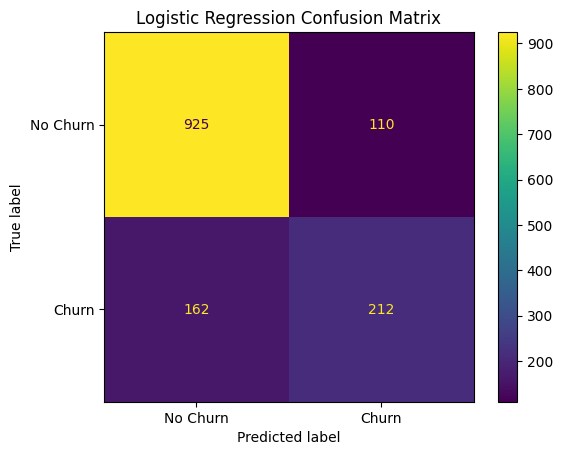

In [37]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["No Churn", "Churn"]
)
disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()


In [38]:
probability_examples = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": y_pred_lr[:10],
    "P(No Churn)": y_prob_lr[:10, 0],
    "P(Churn)": y_prob_lr[:10, 1]
})

display(probability_examples)


,Actual,Predicted,P(No Churn),P(Churn)
0,0,0,0.954466,0.045534
1,0,1,0.316557,0.683443
2,0,0,0.943895,0.056105
3,0,0,0.591612,0.408388
4,0,0,0.978357,0.021643
5,0,1,0.396444,0.603556
6,0,0,0.548489,0.451511
7,0,0,0.868699,0.131301
8,0,0,0.997213,0.002787
9,1,0,0.605876,0.394124


These probabilities represent the model’s estimated probability that each customer belongs to No Churn (0) or Churn (1). predict() selects the class with the higher probability; for example, customer 1 has 68.34% churn probability, so it is predicted as Churn (1).

In [39]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred, zero_division=0)
    })

knn_results_df = pd.DataFrame(knn_results)
display(knn_results_df)


,K,Accuracy,F1
0,1,0.712562,0.469201
1,3,0.738112,0.508655
2,5,0.748758,0.522911
3,7,0.753016,0.529730
4,9,0.768630,0.553425
5,11,0.761533,0.535912
6,15,0.772889,0.558011
7,21,0.775727,0.564738


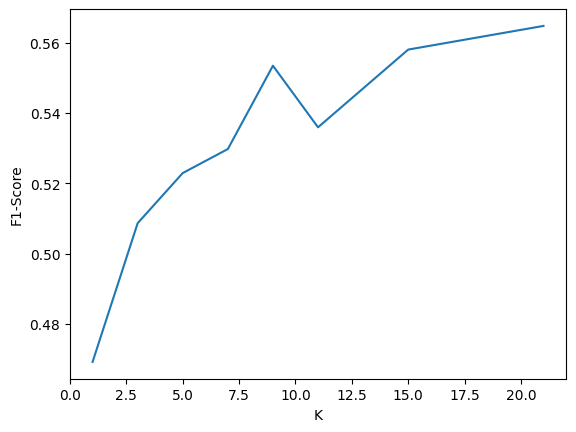

In [40]:
plt.plot(knn_results_df["K"], knn_results_df["F1"], label="F1-score")
plt.xlabel("K")
plt.ylabel("F1-Score")
plt.show()


In [41]:
final_knn = KNeighborsClassifier(n_neighbors=21)
final_knn.fit(X_train_scaled, y_train)

y_pred_knn = final_knn.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn, zero_division=0)
knn_recall = recall_score(y_test, y_pred_knn, zero_division=0)
knn_f1 = f1_score(y_test, y_pred_knn, zero_division=0)

print(f"Chosen K: {21}")
print(f"Accuracy:  {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall:    {knn_recall:.4f}")
print(f"F1-score:  {knn_f1:.4f}")


Chosen K: 21
Accuracy:  0.7757
Precision: 0.5824
Recall:    0.5481
F1-score:  0.5647


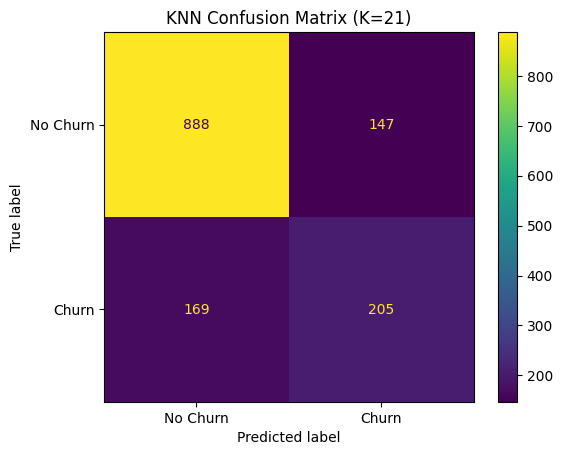

In [42]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["No Churn", "Churn"]
)
disp.plot()
plt.title(f"KNN Confusion Matrix (K={best_k})")
plt.show()


The final KNN model uses K =21. The confusion matrix shows how many churn and non-churn customers were classified correctly and incorrectly.


In [43]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest", "Logistic Regression", "KNN"],
    "Accuracy": [
        dt_results["Accuracy"],
        rf_results["Accuracy"],
        lr_accuracy,
        knn_accuracy
    ],
    "Precision": [
        dt_results["Precision"],
        rf_results["Precision"],
        lr_precision,
        knn_precision
    ],
    "Recall": [
        dt_results["Recall"],
        rf_results["Recall"],
        lr_recall,
        knn_recall
    ],
    "F1": [
        dt_results["F1"],
        rf_results["F1"],
        lr_f1,
        knn_f1
    ]
})

display(comparison)


,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,0.719659,0.473008,0.491979,0.482307
1,Random Forest,0.787083,0.626712,0.489305,0.549550
2,Logistic Regression,0.806955,0.658385,0.566845,0.609195
3,KNN,0.775727,0.582386,0.548128,0.564738


Overall: Logistic Regression performs best, with the highest Accuracy (0.807), Precision (0.658), Recall (0.567), and F1 (0.609). 

Ranking changes by metric: Yes—Random Forest has higher Precision than KNN, while Logistic Regression leads both Precision and Recall; KNN has slightly higher Recall than Random Forest.   

Most important metric: Because there is class imbalance F1-score matters more than accuracy because it balances precision and recall.

In [44]:
feature_names = X.columns

coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": logreg.coef_[0]
})

coef_table["Odds Ratio"] = np.exp(coef_table["Coefficient"])
coef_table["Abs Coefficient"] = coef_table["Coefficient"].abs()

coef_table = coef_table.sort_values(
    "Abs Coefficient", ascending=False
).drop(columns=["Abs Coefficient"])

display(coef_table)


,Feature,Coefficient,Odds Ratio
1,tenure,-1.252707,0.285730
2,MonthlyCharges,-1.003050,0.366759
3,TotalCharges,0.531200,1.700972
16,InternetService_Fiber optic,0.440579,1.553607
15,InternetService_DSL,-0.352482,0.702941
38,Contract_Two year,-0.324018,0.723237
36,Contract_Month-to-month,0.306581,1.358772
32,StreamingTV_Yes,0.187716,1.206490
35,StreamingMovies_Yes,0.187647,1.206408
17,InternetService_No,-0.124808,0.882667


In [45]:
top4 = coef_table.head(4).copy()

display(top4)


,Feature,Coefficient,Odds Ratio
1,tenure,-1.252707,0.285730
2,MonthlyCharges,-1.003050,0.366759
3,TotalCharges,0.531200,1.700972
16,InternetService_Fiber optic,0.440579,1.553607


There is strong agreement between the three labs, with one notable disagreement:

Tenure: Lab 2 identified it as important, Lab 3 ranked it 3rd, and Lab 6 confirms a strong effect (coefficient −1.253, odds ratio 0.286).

MonthlyCharges: Lab 2 identified it as relevant and Lab 3 ranked it 5th; Lab 6 also shows a strong effect (−1.003, odds ratio 0.367).

InternetService_Fiber optic: Lab 2 identified Internet Service as relevant, Lab 3 ranked it 2nd, and Lab 6 also shows an effect (odds ratio 1.554).

TotalCharges: Lab 3 ranked it 4th, and Lab 6 shows an effect (odds ratio 1.701), although I didn't specifically highlighted it in Lab 2 EDA.

Disagreement: Contract was the strongest feature in Lab 3, but it does not appear among Lab 6's four largest coefficients. This shows that different models can identify different features as most influential.

Final Model

I selected **Logistic Regression** as my final model because it achieved the highest Accuracy (0.806955), Precision (0.658385), Recall (0.566845), and F1-score (0.609195) among the four models. However, based on Lab 4's cross-validation lesson, I would not rely on a single test-set score; the model should also be evaluated across multiple folds to confirm that its performance is consistent.


Conclusion

Logistic Regression performed slightly better than the Tuned Random Forest from Lab 4, achieving 80.70% accuracy and a 60.92% F1-score compared with 80.62% accuracy and a 59.31% F1-score. It also improved on the Decision Tree from Lab 3, which achieved 79.84% accuracy and a 59.89% F1-score. Feature scaling was important for Logistic Regression and KNN because these models are affected by feature magnitudes, unlike the tree-based models. Logistic Regression still has moderate recall, meaning it misses some actual churn cases. Its performance may also be affected by the quality and selection of features. Since Lab 4 showed the importance of cross-validation, I would next use cross-validation and hyperparameter tuning to check whether Logistic Regression consistently performs better.
